## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kamal Sangam

**Date:** Oct 14 2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Consistent appearance for the graphs.
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


## Q1 — How does noise affect k-means?

### Q1.1 Create the five datasets

In [2]:
def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    # Generate (x1, x2, g) triples:
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

noise_data = {
    0.125: df0_125, 0.25: df0_25, 0.5: df0_5,
    1.0: df1_0, 2.0: df2_0
}
print('Created datasets (rows each):', {noise: len(df) for noise, df in noise_data.items()})

Created datasets (rows each): {0.125: 150, 0.25: 150, 0.5: 150, 1.0: 150, 2.0: 150}


### Q1.2 Scatterplots colored by original group

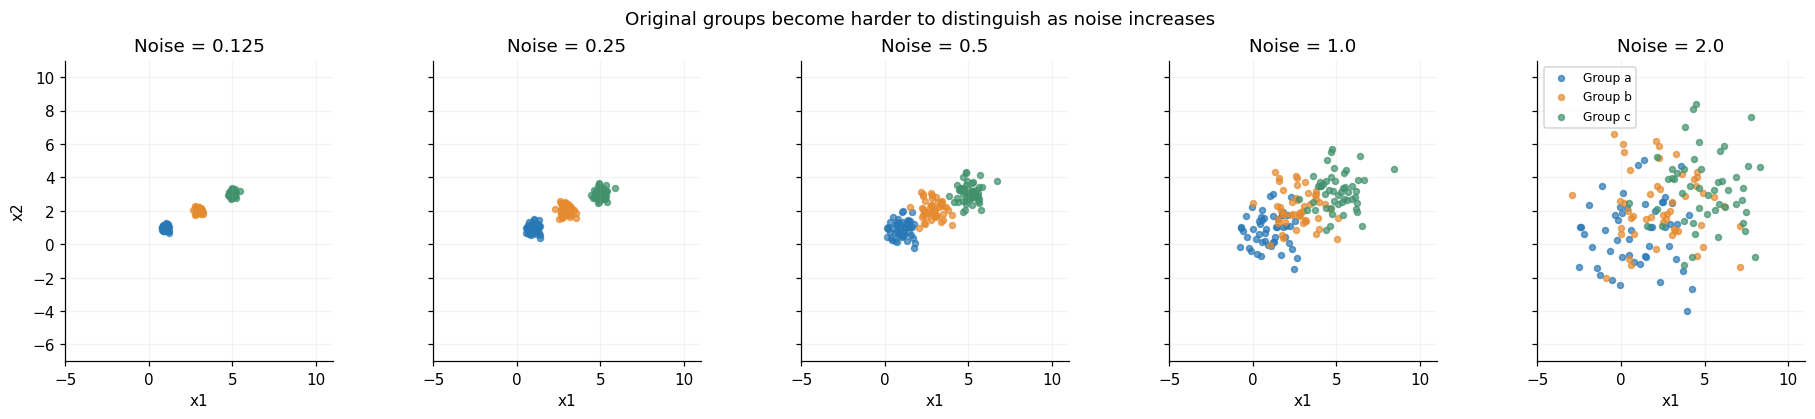

In [3]:
# Same x/y limits and aspect ratio in every panel makes comparisons fair.
fig, axes = plt.subplots(1, 5, figsize=(17, 3.7), sharex=True, sharey=True, constrained_layout=True)
colors = {'a': '#2878B5', 'b': '#E68A2E', 'c': '#40916C'}

for ax, (noise, df) in zip(axes, noise_data.items()):
    for group in ['a', 'b', 'c']:
        points = df[df['group'] == group]
        ax.scatter(points['x1'], points['x2'], s=15, alpha=0.70,
                   color=colors[group], label=f'Group {group}')
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.15)
axes[0].set_ylabel('x2')
axes[0].set_xlim(-5, 11)
axes[0].set_ylim(-7, 11)
axes[-1].legend(loc='upper left', fontsize=8)
fig.suptitle('Original groups become harder to distinguish as noise increases', fontsize=12)
plt.show()

**Q1.2 Answer:** At noise = 0.125 and 0.25, the three groups form tight, clearly separated clouds. At 0.5 they spread out but are mostly distinguishable. At 1.0 the groups overlap much more; by 2.0 the points are widely scattered and the original groups mix together. Larger standard deviation means each observation can land farther from its group's center, so the visual boundaries become less obvious.

### Q1.3 Scree plots for all five datasets

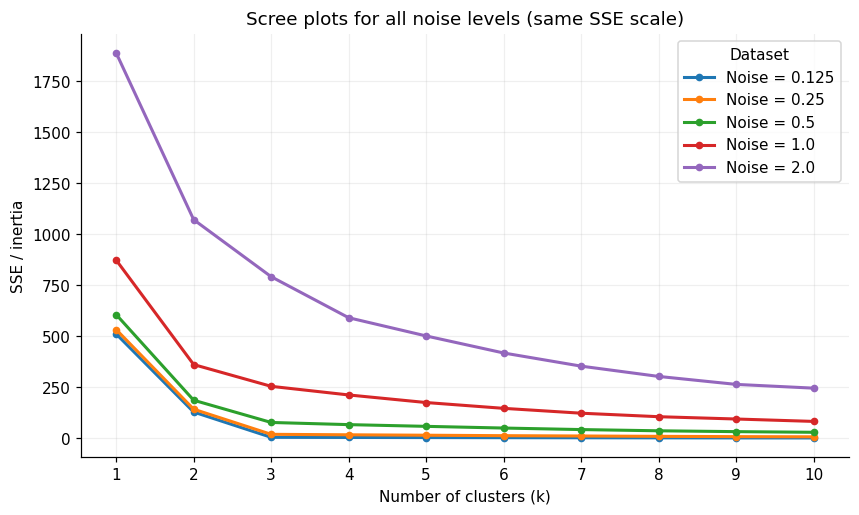

SSE by noise and k (first five k values):


,0.125,0.25,0.5,1.0,2.0
k,,,,,
1,511.61,533.25,606.62,873.69,1889.20
2,128.89,142.72,186.78,361.59,1071.81
3,4.91,19.65,77.82,254.91,792.27
4,4.33,17.33,67.19,212.65,591.18
5,3.80,15.24,58.74,175.47,501.88


In [4]:
def get_sse(X, max_k=10):
    """Return total within-cluster squared distance for k = 1 ... max_k."""
    values = []
    for k in range(1, max_k + 1):
        model = KMeans(n_clusters=k, n_init=10, random_state=0)
        model.fit(X)
        values.append(model.inertia_)
    return values

ks = list(range(1, 11))
q1_sse = {}
for noise, df in noise_data.items():
    q1_sse[noise] = get_sse(df[['x1', 'x2']], max_k=10)

# One panel with common axes prevents the changing vertical scale from misleading us.
fig, ax = plt.subplots(figsize=(9, 5))
for noise, sse in q1_sse.items():
    ax.plot(ks, sse, marker='o', markersize=4, linewidth=2, label=f'Noise = {noise}')
ax.set(title='Scree plots for all noise levels (same SSE scale)',
       xlabel='Number of clusters (k)', ylabel='SSE / inertia')
ax.set_xticks(ks)
ax.grid(alpha=0.2)
ax.legend(title='Dataset')
plt.show()

# Print some numbers to help explain the elbow.
print('SSE by noise and k (first five k values):')
display(pd.DataFrame({str(n): scores[:5] for n, scores in q1_sse.items()},
                     index=range(1, 6)).round(2).rename_axis('k'))

**Q1.3 Answer:** At low noise, SSE drops rapidly as k increases from 1 toward **3**, then the improvements get much smaller. This makes k = 3 a convincing elbow and matches the three groups used to generate the data. As noise rises, SSE is higher overall (especially at k = 1), because points are farther from their centers. At high noise, SSE continues dropping appreciably beyond k = 3, making the elbow **less distinct**. Choosing k from the graph becomes more subjective, even though we know the simulation originally generated three groups. The five curves share one vertical scale, so their heights are directly comparable. Note that a high-noise curve can have a different bend from the true generating-group count.

### Q1.4 Why does the elbow make sense?

K-means reduces **SSE**, the sum of squared distances from each point to its assigned centroid. With **k = 1**, all three groups must share one centroid, producing large errors. With **k = 2**, some groups still have to be combined. Increasing to **k = 3** can give each original group a center, causing a large reduction in error when the groups are distinct. Beyond that, extra centers mostly split up groups that already fit reasonably well, so the additional improvement is smaller. The *elbow* is where the large benefits start to level off. With high noise, clusters overlap and there may be no single, convincing point where this happens. We do **not** choose the k with the absolute lowest SSE because adding clusters almost always reduces SSE.

## Q2 — SIPRI military expenditure (2020)

### Q2.1 Read, filter, clean, and check the data

In [14]:
from pathlib import Path

filename = 'SIPRI Military Expenditure Database.csv'
csv_path = Path('data', filename)

raw = pd.read_csv(csv_path)
spending_columns = [
    'Spending (2020 USD)', 'Spending per Capita',
    'Percent of Government Spending', 'Percent of GDP'
]

countries = raw[raw['Year'] == 2020].dropna().copy()
print('2020 rows before dropna:', len(raw[raw['Year'] == 2020]))
print('2020 rows after dropna:', len(countries))
print('Data types:')
print(countries[spending_columns].dtypes)
print('Duplicate country names:', countries['Country'].duplicated().sum())
print('Remaining null values:', countries.isna().sum().sum())
print('Min/max for numeric columns:')
display(countries[spending_columns].agg(['min', 'max']).round(4))
print('Sample rows:')
display(countries[['Country'] + spending_columns].head())

2020 rows before dropna: 173
2020 rows after dropna: 148
Data types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
Duplicate country names: 0
Remaining null values: 0
Min/max for numeric columns:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,8.6225,0.5801,0.0049,0.0001
max,778397.2000,2520.3985,0.3030,0.0985


Sample rows:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
32,Afghanistan,279.576955,7.181899,0.049728,0.013589
66,Albania,187.433234,65.126211,0.037952,0.012583
100,Algeria,9708.277440,221.392384,0.173924,0.066600
134,Angola,993.594405,30.231680,0.074624,0.014442
168,Argentina,2830.929705,62.636731,0.017268,0.007269


**Q2.1 Answer:** Filtering to 2020 and dropping rows with missing values leaves **148 countries** (from 173 records in 2020). The four spending columns are already numeric floats, so we do not need to remove currency symbols, percent signs, or commas. The percentage columns are stored as decimal proportions (for example, 0.04 means 4%), and should be left that way for modeling. The `index` column is only an old row identifier, not a useful clustering feature. There are no duplicated country names after filtering. We should **scale the four numeric features before k-means**, because their original units and ranges differ greatly.

### Reusable helper functions

In [6]:
def maxmin(x):
    """Scale a column to the range 0 to 1."""
    return (x - x.min()) / (x.max() - x.min())


def make_scree(X, title, max_k=10):
    """Plot SSE for different choices of k."""
    scores = get_sse(X, max_k)
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, max_k + 1), scores, marker='o', linewidth=2)
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('SSE / inertia')
    plt.title(title)
    plt.xticks(range(1, max_k + 1))
    plt.grid(alpha=0.2)
    plt.show()
    return scores


def fit_clusters(df, columns, k):
    """Return a copy of the data with k-means cluster labels."""
    result = df.copy()
    X = result[columns].apply(maxmin)
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    result['cluster'] = model.fit_predict(X)
    return result, model


def show_cluster_plot(df, x, y, title):
    """Scatter plot in original data units, colored by cluster."""
    plt.figure(figsize=(8, 5))
    for cluster in sorted(df['cluster'].unique()):
        points = df[df['cluster'] == cluster]
        plt.scatter(points[x], points[y], alpha=0.75, s=35,
                    label=f'Cluster {cluster} (n={len(points)})')
    #emphasize the US 
    usa = df[df['Country'] == 'United States of America']
    if not usa.empty:
        plt.scatter(usa[x], usa[y], marker='*', s=230,
                    facecolors='none', edgecolors='black', linewidths=1.6,
                    label='United States', zorder=10)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(title)
    plt.legend(fontsize=8)
    plt.grid(alpha=0.16)
    plt.tight_layout()
    plt.show()


def summarize_clusters(df, columns):
    """Show how many countries are in each cluster and a describe table."""
    print('Countries per cluster:')
    display(df['cluster'].value_counts().sort_index().rename('countries').to_frame())
    print('Describe table by cluster (original units):')
    display(df.groupby('cluster')[columns].describe().round(3))
    print('Cluster means (easier to compare):')
    display(df.groupby('cluster')[columns].mean().round(3))


### Q2.2 Spending (2020 USD) vs spending per capita

Normalized values (first five rows):


,Spending (2020 USD),Spending per Capita
32,0.000,0.003
66,0.000,0.026
100,0.012,0.088
134,0.001,0.012
168,0.004,0.025


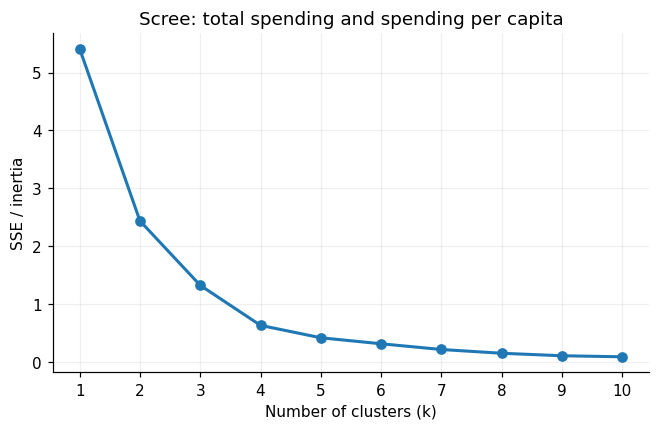

In [7]:
amount_cols = ['Spending (2020 USD)', 'Spending per Capita']
amount_X = countries[amount_cols].apply(maxmin)
print('Normalized values (first five rows):')
display(amount_X.head().round(3))
amount_sse = make_scree(amount_X, 'Scree: total spending and spending per capita')

**Choice of k:** The scree plot is steep initially, then flattens so **k = 3** is a reasonable interpretable choice, separating the broad majority from unusually high-spending observations. Since large outliers influence k-means, this choice is not uniquely determined by the elbow.

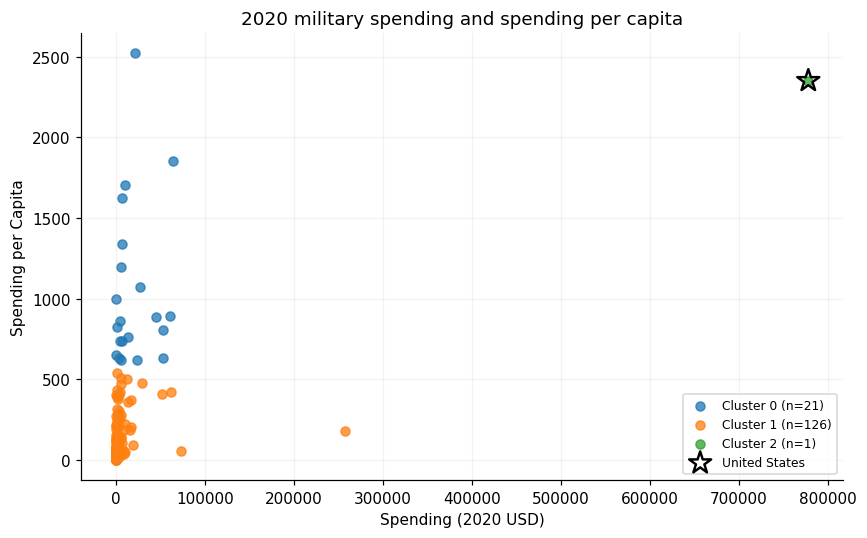

Countries per cluster:


,countries
cluster,
0,21
1,126
2,1


Describe table by cluster (original units):


Spending (2020 USD)                                                 \
                      count        mean        std         min         25%   
cluster                                                                      
0                      21.0   19975.991  21749.737     405.790    4980.428   
1                     126.0    5943.346  24858.961       8.622     162.762   
2                       1.0  778397.200        NaN  778397.200  778397.200   

                                           Spending per Capita            \
                50%         75%        max               count      mean   
cluster                                                                    
0          7269.880   27300.895   64558.40                21.0  1046.434   
1           580.758    3225.333  257973.43               126.0   122.035   
2        778397.200  778397.200  778397.20                 1.0  2351.632   

                                                                    
             std       min       25%       50%       75%       max  
cluster                                                             
0        501.632   616.854   737.690   859.881  1193.599  2520.399  
1        140.041     0.580    18.506    58.809   188.249   541.155  
2            NaN  2351.632  2351.632  2351.632  2351.632  2351.632

Cluster means (easier to compare):


,Spending (2020 USD),Spending per Capita
cluster,,
0,19975.991,1046.434
1,5943.346,122.035
2,778397.200,2351.632


United States:


,Country,cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


Countries in clusters with five or fewer members:
Cluster 2 : United States of America


In [8]:
amount_k = 3
amount_clusters, amount_model = fit_clusters(countries, amount_cols, amount_k)
show_cluster_plot(amount_clusters, amount_cols[0], amount_cols[1],
                  '2020 military spending and spending per capita')
summarize_clusters(amount_clusters, amount_cols)
print('United States:')
display(amount_clusters.loc[amount_clusters['Country'] == 'United States of America',
                            ['Country', 'cluster'] + amount_cols])
print('Countries in clusters with five or fewer members:')
for cluster, count in amount_clusters['cluster'].value_counts().items():
    if count <= 5:
        print('Cluster', cluster, ':', ', '.join(amount_clusters.loc[
            amount_clusters['cluster'] == cluster, 'Country']))

**Q2.2 Answer:** Total spending and spending per capita are very unevenly distributed. Most countries cluster near the lower-left, while a small number have very large totals and/or high per-person spending. The **United States is an extreme high-total-spending country**, marked by the outlined star and its exact cluster number is printed in the table above. China also spends a large amount overall but much less per person than the U.S. Spending per capita and total spending do not tell the same story: population size helps explain why some big-total spenders have relatively modest per-person values. Because k-means uses distances, a few extreme countries strongly affect the cluster locations.

### Q2.3 Percent of government spending vs percent of GDP

Normalized values (first five rows):


,Percent of Government Spending,Percent of GDP
32,0.150,0.138
66,0.111,0.127
100,0.567,0.676
134,0.234,0.146
168,0.041,0.073


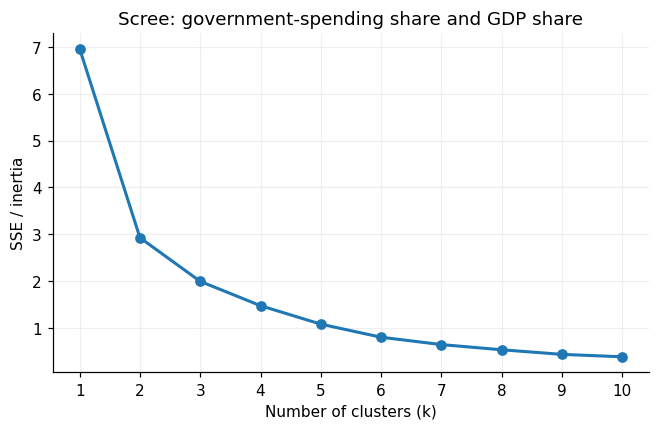

In [9]:
percent_cols = ['Percent of Government Spending', 'Percent of GDP']
percent_X = countries[percent_cols].apply(maxmin)
print('Normalized values (first five rows):')
display(percent_X.head().round(3))
percent_sse = make_scree(percent_X, 'Scree: government-spending share and GDP share')

**Choice of k:** **k = 3** provides a simple grouping of low, middle and high military-spending shares. The curve does not identify one indisputably correct k, so we treat the result as an exploratory grouping.

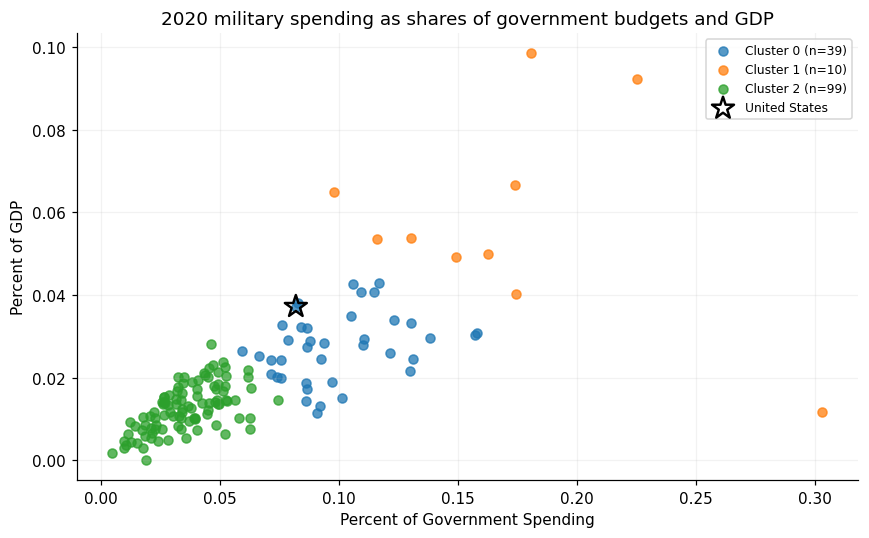

Countries per cluster:


,countries
cluster,
0,39
1,10
2,99


Describe table by cluster (original units):


Percent of Government Spending                                     \
                                 count   mean    std    min    25%    50%   
cluster                                                                     
0                                 39.0  0.099  0.024  0.060  0.082  0.092   
1                                 10.0  0.171  0.059  0.098  0.135  0.168   
2                                 99.0  0.036  0.015  0.005  0.026  0.034   

                      Percent of GDP                                     \
           75%    max          count   mean    std    min    25%    50%   
cluster                                                                   
0        0.113  0.158           39.0  0.027  0.008  0.011  0.021  0.028   
1        0.179  0.303           10.0  0.058  0.025  0.012  0.049  0.054   
2        0.047  0.075           99.0  0.013  0.006  0.000  0.008  0.013   

                       
           75%    max  
cluster                
0        0.032  0.043  
1        0.066  0.098  
2        0.017  0.028

Cluster means (easier to compare):


,Percent of Government Spending,Percent of GDP
cluster,,
0,0.099,0.027
1,0.171,0.058
2,0.036,0.013


United States:


,Country,cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,0,0.081976,0.037179


Highest GDP-share countries:


,Country,cluster,Percent of Government Spending,Percent of GDP
4044,Oman,1,0.180654,0.098470
4486,Saudi Arabia,1,0.225050,0.092211
100,Algeria,1,0.173924,0.066600
2922,Kuwait,1,0.097882,0.064961
304,Azerbaijan,1,0.130339,0.053905
2582,Israel,1,0.116052,0.053553
202,Armenia,1,0.162572,0.049827
2718,Jordan,1,0.149025,0.049121
3636,Morocco,0,0.116990,0.042810
4418,Russia,0,0.105861,0.042634


In [10]:
percent_k = 3
percent_clusters, percent_model = fit_clusters(countries, percent_cols, percent_k)
show_cluster_plot(percent_clusters, percent_cols[0], percent_cols[1],
                  '2020 military spending as shares of government budgets and GDP')
summarize_clusters(percent_clusters, percent_cols)
print('United States:')
display(percent_clusters.loc[percent_clusters['Country'] == 'United States of America',
                             ['Country', 'cluster'] + percent_cols])
print('Highest GDP-share countries:')
display(percent_clusters.sort_values('Percent of GDP', ascending=False)[
    ['Country', 'cluster'] + percent_cols].head(10))

**Q2.3 Answer:** These two percentages often rise together: countries that devote a larger portion of their government's budget to the military also tend to spend a larger portion of GDP. The clusters describe **relative military priority or burden**, not the absolute amount of money spent. Compared with Q2.2, countries can belong to quite different clusters: a country with a modest total military budget may still devote a large share of its available resources to defense. The United States is not necessarily the most extreme country by either percentage, despite its unusually large dollar total.

### Q2.4 K-means on all four normalized variables

All four normalized features:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
32,0.000,0.003,0.150,0.138
66,0.000,0.026,0.111,0.127
100,0.012,0.088,0.567,0.676
134,0.001,0.012,0.234,0.146
168,0.004,0.025,0.041,0.073


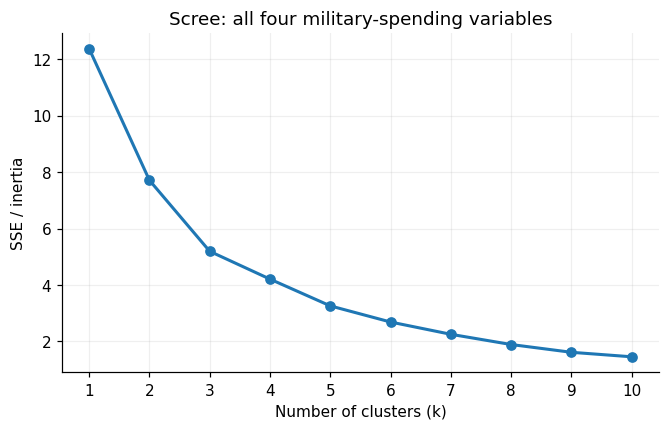

In [11]:
all_X = countries[spending_columns].apply(maxmin)
print('All four normalized features:')
display(all_X.head().round(3))
all_sse = make_scree(all_X, 'Scree: all four military-spending variables')

**Choice of k:** **k = 3** again offers a readable starting point for comparison across the three analyses. A smoother scree curve would also support considering neighboring k values; the elbow method is a guide, not a formal proof.

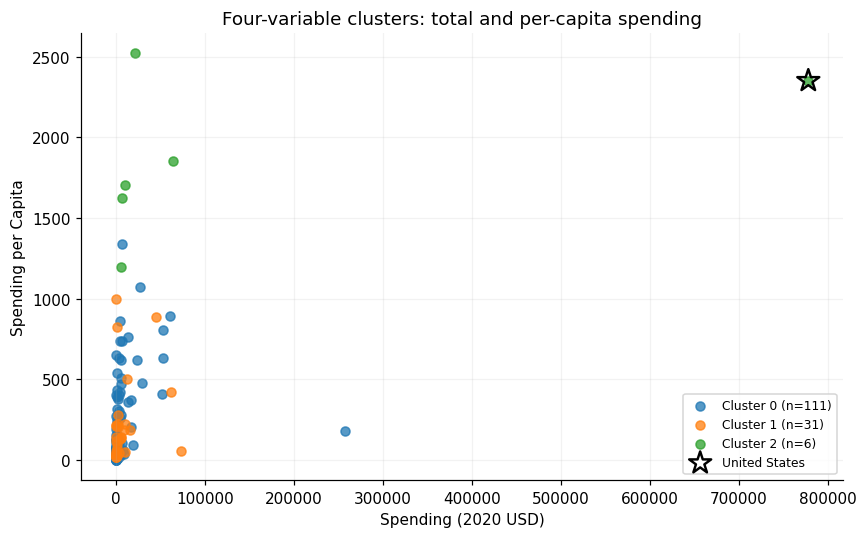

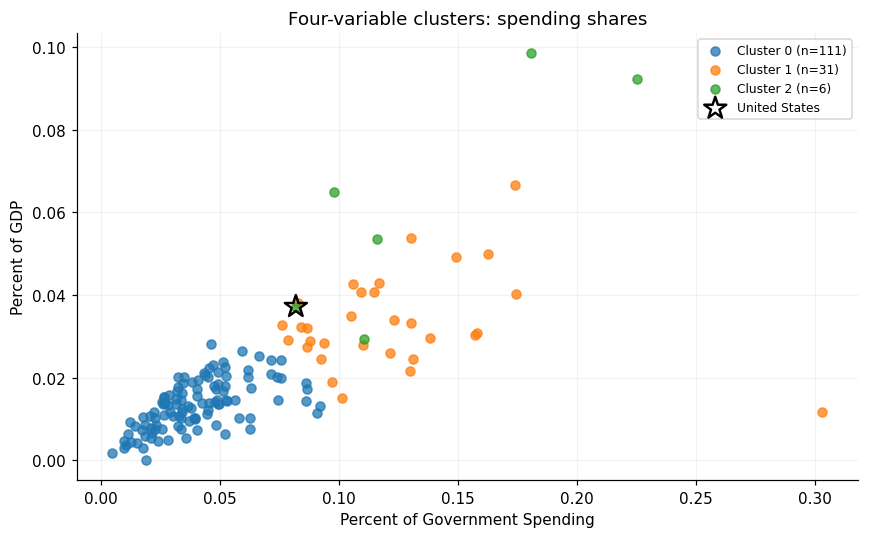

Countries per cluster:


,countries
cluster,
0,111
1,31
2,6


Describe table by cluster (original units):


Spending (2020 USD)                                              \
                      count        mean         std       min       25%   
cluster                                                                   
0                     111.0    7086.473   26479.380     8.622   130.010   
1                      31.0    8786.087   17901.909   162.373   467.788   
2                       6.0  147964.582  309635.190  6095.709  7700.425   

                                          Spending per Capita            ...  \
               50%        75%         max               count      mean  ...   
cluster                                                                  ...   
0          567.651   3910.107  257973.430               111.0   196.927  ...   
1         1404.787   7739.166   72937.064                31.0   212.689  ...   
2        15897.571  53872.942  778397.200                 6.0  1875.151  ...   

        Percent of Government Spending        Percent of GDP                \
                                   75%    max          count   mean    std   
cluster                                                                      
0                                0.051  0.092          111.0  0.013  0.006   
1                                0.135  0.303           31.0  0.033  0.011   
2                                0.165  0.225            6.0  0.063  0.028   

                                            
           min    25%    50%    75%    max  
cluster                                     
0        0.000  0.009  0.014  0.018  0.028  
1        0.012  0.028  0.032  0.041  0.067  
2        0.029  0.041  0.059  0.085  0.098  

[3 rows x 32 columns]

Cluster means (easier to compare):


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster,,,,
0,7086.473,196.927,0.040,0.013
1,8786.087,212.689,0.123,0.033
2,147964.582,1875.151,0.135,0.063


United States:


,Country,cluster,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,2,778397.2,2351.631858,0.081976,0.037179


In [12]:
all_k = 3
all_clusters, all_model = fit_clusters(countries, spending_columns, all_k)
#Two views of the same four variable cluster membership.
show_cluster_plot(all_clusters, amount_cols[0], amount_cols[1],
                  'Four-variable clusters: total and per-capita spending')
show_cluster_plot(all_clusters, percent_cols[0], percent_cols[1],
                  'Four-variable clusters: spending shares')
summarize_clusters(all_clusters, spending_columns)
print('United States:')
display(all_clusters.loc[all_clusters['Country'] == 'United States of America',
                         ['Country', 'cluster'] + spending_columns])

**Q2.4 Comparison:** When we use all four features, membership depends on a mix of **size, spending per person, government-budget share, and GDP share**. A country that stands out in only one pair of variables may be grouped differently when the other pair is added. All four columns were max-min scaled so none dominates just because its raw units are larger. However, normalization does not remove outliers, and the two percentage features are related, so they can reinforce one another's effect on distance. The four-variable results provide a broader profile than either two-variable model, but are harder to show fully in a single two-dimensional scatterplot.

### Compare memberships from all three analyses

In [13]:
comparison = pd.DataFrame({
    'Country': countries['Country'],
    'Total + Per Capita': amount_clusters['cluster'],
    'Government + GDP Shares': percent_clusters['cluster'],
    'All Four': all_clusters['cluster']
})
print('United States across the three models:')
display(comparison[comparison['Country'] == 'United States of America'])
print('Example countries (clusters are arbitrary numeric labels):')
examples = ['United States of America', 'China', 'Saudi Arabia', 'India', 'Germany']
display(comparison[comparison['Country'].isin(examples)].sort_values('Country'))

United States across the three models:


,Country,Total + Per Capita,Government + GDP Shares,All Four
5540,United States of America,2,0,2


Example countries (clusters are arbitrary numeric labels):


,Country,Total + Per Capita,Government + GDP Shares,All Four
1052,China,1,2,0
2038,Germany,0,2,0
2412,India,1,0,1
4486,Saudi Arabia,0,1,2
5540,United States of America,2,0,2


### Q2.5 Were the patterns useful?

**Yes, with limitations.** K-means highlights that high *total* military spending, high *per-capita* spending, and high *shares of GDP/government spending* are different characteristics. Looking only at absolute dollars can hide the relative burden on smaller economies. Using different combinations of variables reveals that cluster membership depends on what we mean by "similar spending." But these are **descriptive**, not causal, patterns. Outliers such as the U.S. can pull centroids, min-max scaling can compress most countries into a small part of the range, and there is not always a clear elbow. Cluster labels also do not tell us whether a country's spending is appropriate or why it spends that amount. Overall, k-means is useful for generating comparisons and identifying unusual observations, not for giving one definitive classification of countries.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]